## Cell 1 — Import thư viện và cố định seed

- `torch`: huấn luyện mạng nơ-ron.
- `torchvision`: đọc ảnh và sử dụng ResNet-18 có sẵn.
- `sklearn`: chia dữ liệu và tính độ đo.
- `matplotlib`: vẽ kết quả.
- `seed`: giúp phép chia và huấn luyện dễ tái lập hơn.

In [1]:
import random
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from torch import nn, optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Thiết bị:', device)

Thiết bị: cuda


In [2]:

DATA_ROOT = Path(
    "/kaggle/input/datasets/ayush02102001/circuit-component-analysis/CktComDb-v1.oa"
)

print("Dataset tồn tại:", DATA_ROOT.exists())

for path in DATA_ROOT.iterdir():
    print(path.name)

assert DATA_ROOT.exists(), 'Chưa Add Input dataset JUHCCR-v1-A vào notebook Kaggle.'

Dataset tồn tại: True
CktComDb-v1.oa


## Cell 3 — Chọn đúng thư mục train/test

In [3]:
pairs = []
for folder in DATA_ROOT.rglob('*'):
    if folder.is_dir() and folder.name.lower().startswith('train'):
        tests = [p for p in folder.parent.iterdir()
                 if p.is_dir() and p.name.lower().startswith('test')]
        num_classes = sum(p.is_dir() for p in folder.iterdir())
        if tests and num_classes >= 10:
            pairs.append((folder, tests[0]))

for i, (tr, te) in enumerate(pairs):
    print(f'{i}: TRAIN = {tr}\n   TEST  = {te}')

assert pairs, 'Không tìm thấy cặp Train/Test. Hãy xem lại cấu trúc ở Cell 2.'
DATASET_ID = 0  # Đổi số này nếu bản .a không ở vị trí 0
TRAIN_DIR, TEST_DIR = pairs[DATASET_ID]
print('Đang sử dụng:', TRAIN_DIR, '\n', TEST_DIR)

0: TRAIN = /kaggle/input/datasets/ayush02102001/circuit-component-analysis/CktComDb-v1.oa/CktComDb-v1.oa/Train
   TEST  = /kaggle/input/datasets/ayush02102001/circuit-component-analysis/CktComDb-v1.oa/CktComDb-v1.oa/Test
Đang sử dụng: /kaggle/input/datasets/ayush02102001/circuit-component-analysis/CktComDb-v1.oa/CktComDb-v1.oa/Train 
 /kaggle/input/datasets/ayush02102001/circuit-component-analysis/CktComDb-v1.oa/CktComDb-v1.oa/Test


## Cell 4 — Tiền xử lý ảnh

In [4]:
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32

transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

## Cell 5 — Đọc bộ dữ liệu và các lớp ký hiệu

In [5]:

import re

# 1. Đọc dữ liệu
full_train = datasets.ImageFolder(TRAIN_DIR, transform=transform)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=transform)

classes = full_train.classes

# 2. Tên 20 loại linh kiện theo JUHCCR-v1
class_names = {
    1: "AC Source",
    2: "Ammeter",
    3: "AND Gate",
    4: "Capacitor",
    5: "DC Source",
    6: "Ground",
    7: "Inductor",
    8: "NAND Gate",
    9: "NOR Gate",
    10: "NOT Gate",
    11: "NPN Transistor",
    12: "OR Gate",
    13: "PN Junction Diode",
    14: "PNP Transistor",
    15: "Power Supply",
    16: "Resistor",
    17: "Switch",
    18: "Transformer",
    19: "Voltmeter",
    20: "Zener Diode"
}

# 3. Kiểm tra số lớp
assert len(classes) == 20, "Dataset phải có 20 lớp."
assert full_train.class_to_idx == test_dataset.class_to_idx

# 4. Ánh xạ tên thư mục sang tên linh kiện
display_names = []

for folder in classes:
    match = re.match(r"^(\d+)", folder)

    if match is None:
        raise ValueError(f"Không tìm thấy mã lớp trong: {folder}")

    class_id = int(match.group(1))
    display_names.append(class_names[class_id])

# 5. Hiển thị kết quả
print("Số lớp:", len(classes))
print("Số ảnh Train:", len(full_train))
print("Số ảnh Test:", len(test_dataset))

print("\nDanh sách 20 classes:")
for i, name in enumerate(display_names):
    print(f"{i}: {name}")


Số lớp: 20
Số ảnh Train: 10010
Số ảnh Test: 20000

Danh sách 20 classes:
0: AC Source
1: Ammeter
2: AND Gate
3: Capacitor
4: DC Source
5: Ground
6: Inductor
7: NAND Gate
8: NOR Gate
9: NOT Gate
10: NPN Transistor
11: OR Gate
12: PN Junction Diode
13: PNP Transistor
14: Power Supply
15: Resistor
16: Switch
17: Transformer
18: Voltmeter
19: Zener Diode


## Cell 6 — Hiển thị 6 ảnh mẫu


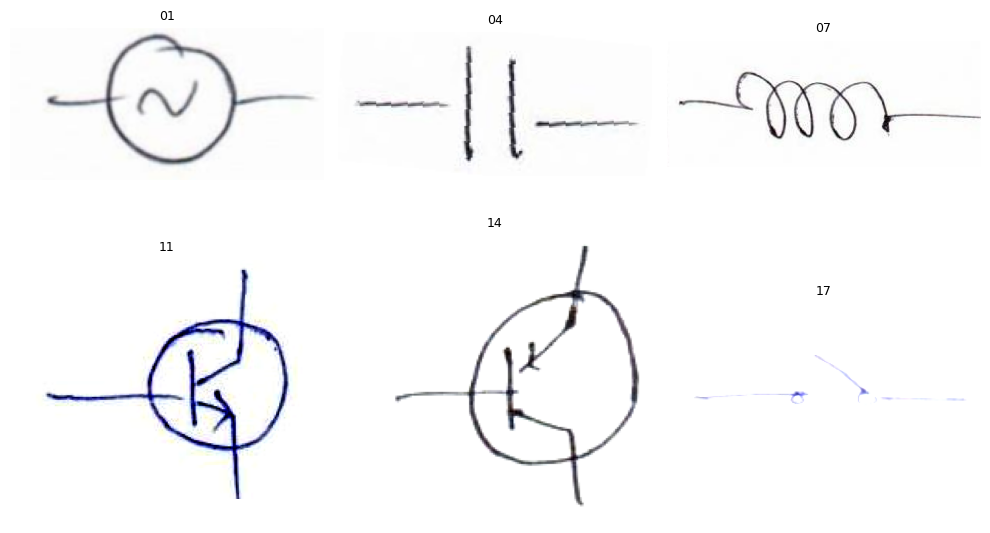

In [6]:
plt.figure(figsize=(10, 6))
for i in range(6):
    image_path, label = full_train.samples[i * max(1, len(full_train) // 6)]
    image = Image.open(image_path).convert('RGB')
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(classes[label], fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Cell 7 — Chia training thành train và validation (80/20)

In [7]:
groups = []
for file_path, label in full_train.samples:
    stem = Path(file_path).stem
    match = re.search(r'(\d+)$', stem)
    source_id = match.group(1) if match else stem
    groups.append(f'{label}_{source_id}')

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(splitter.split(full_train, groups=groups))

train_dataset = Subset(full_train, train_idx)
val_dataset = Subset(full_train, val_idx)
print('Train:', len(train_dataset))
print('Validation:', len(val_dataset))
print('Test:', len(test_dataset))
print('Số group chung train/val:', len(set(np.array(groups)[train_idx]) &
                                   set(np.array(groups)[val_idx])))

Train: 8008
Validation: 2002
Test: 20000
Số group chung train/val: 0


## Cell 8 — DataLoader

In [8]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

## Cell 9 — Khởi tạo ResNet-18 (Transfer Learning)

In [9]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for param in model.parameters():
    param.requires_grad = False

for param in model.layer4.parameters():
    param.requires_grad = True

model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)
print('Lớp phân loại mới:', model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]


Lớp phân loại mới: Linear(in_features=512, out_features=20, bias=True)


## Cell 10 — Loss function, optimizer và tham số huấn luyện

In [10]:
EPOCHS = 8
LEARNING_RATE = 1e-4

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE
)

## Cell 11 — Hàm chạy một epoch

In [11]:
def run_epoch(loader, training):
    model.train() if training else model.eval()
    if training:
        model.bn1.eval()
        model.layer1.eval()
        model.layer2.eval()
        model.layer3.eval()

    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

## Cell 12 — Huấn luyện và lưu mô hình tốt nhất

In [12]:
history = {'train_acc': [], 'val_acc': []}
best_val_acc = 0.0
SAVE_PATH = '/kaggle/working/resnet18_juhccr_v1a.pth'

for epoch in range(EPOCHS):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)

    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    print(f'Epoch {epoch+1}/{EPOCHS} | '
          f'Train loss: {train_loss:.4f}, acc: {train_acc:.2%} | '
          f'Val loss: {val_loss:.4f}, acc: {val_acc:.2%}')

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({'model': model.state_dict(), 'classes': classes}, SAVE_PATH)

print('Validation accuracy tốt nhất:', f'{best_val_acc:.2%}')
print('Đã lưu:', SAVE_PATH)

Epoch 1/8 | Train loss: 0.4313, acc: 88.89% | Val loss: 0.0695, acc: 98.00%
Epoch 2/8 | Train loss: 0.0378, acc: 99.34% | Val loss: 0.0290, acc: 99.15%
Epoch 3/8 | Train loss: 0.0132, acc: 99.76% | Val loss: 0.0182, acc: 99.40%
Epoch 4/8 | Train loss: 0.0100, acc: 99.78% | Val loss: 0.0153, acc: 99.65%
Epoch 5/8 | Train loss: 0.0080, acc: 99.81% | Val loss: 0.0112, acc: 99.55%
Epoch 6/8 | Train loss: 0.0079, acc: 99.80% | Val loss: 0.0147, acc: 99.40%
Epoch 7/8 | Train loss: 0.0042, acc: 99.90% | Val loss: 0.0093, acc: 99.60%
Epoch 8/8 | Train loss: 0.0028, acc: 99.89% | Val loss: 0.0101, acc: 99.70%
Validation accuracy tốt nhất: 99.70%
Đã lưu: /kaggle/working/resnet18_juhccr_v1a.pth


## Cell 13 — Vẽ đồ thị accuracy

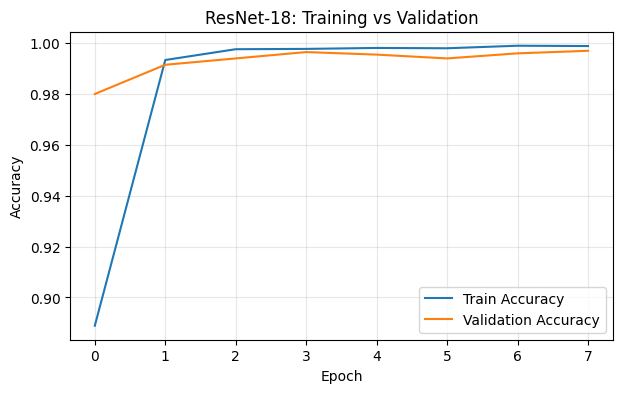

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(history['train_acc'], label='Train Accuracy')
plt.plot(history['val_acc'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('ResNet-18: Training vs Validation')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Cell 14 — Đánh giá cuối cùng trên test

In [14]:

checkpoint = torch.load(SAVE_PATH, map_location=device, weights_only=True)
model.load_state_dict(checkpoint['model'])
model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu().tolist()

        y_pred.extend(predictions)
        y_true.extend(labels.tolist())

accuracy = (np.array(y_true) == np.array(y_pred)).mean()

print('TEST ACCURACY:', f'{accuracy:.2%}')

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    target_names=display_names,
    zero_division=0,
    digits=4
))


TEST ACCURACY: 94.94%
                   precision    recall  f1-score   support

        AC Source     0.8185    0.9200    0.8663      1000
          Ammeter     0.9279    0.8880    0.9075      1000
         AND Gate     0.9305    0.9640    0.9470      1000
        Capacitor     0.9910    0.9910    0.9910      1000
        DC Source     0.9842    0.9980    0.9911      1000
           Ground     1.0000    0.9970    0.9985      1000
         Inductor     0.9866    0.9590    0.9726      1000
        NAND Gate     0.9674    0.9210    0.9436      1000
         NOR Gate     0.9234    0.9770    0.9495      1000
         NOT Gate     0.9331    0.9900    0.9607      1000
   NPN Transistor     0.9330    0.9330    0.9330      1000
          OR Gate     0.9829    0.9210    0.9510      1000
PN Junction Diode     0.8769    0.9120    0.8941      1000
   PNP Transistor     0.9283    0.9450    0.9366      1000
     Power Supply     0.9970    0.9970    0.9970      1000
         Resistor     0.9642    0

## Cell 15 — Confusion Matrix

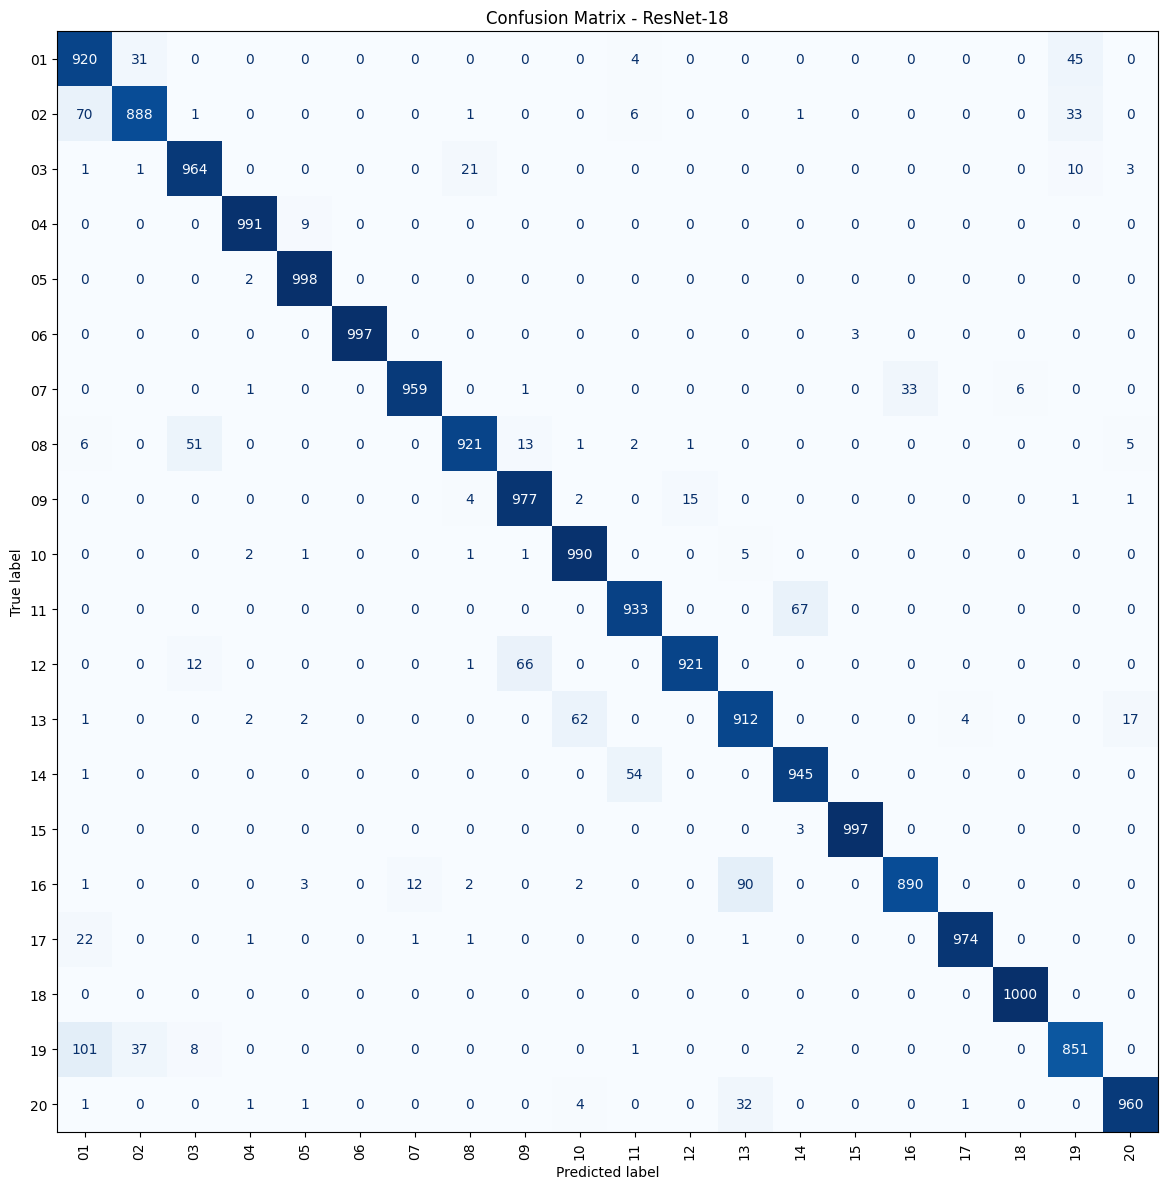

In [15]:
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    labels=list(range(len(classes))),
    display_labels=classes,
    xticks_rotation=90, cmap='Blues', ax=ax, colorbar=False
)
plt.title('Confusion Matrix - ResNet-18')
plt.tight_layout()
plt.show()

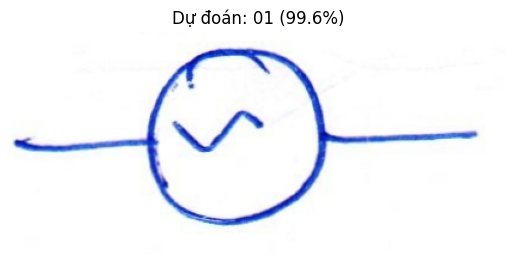

In [16]:
IMAGE_PATH = test_dataset.samples[0][0]  # Có thể thay bằng ảnh tự tải lên
image = Image.open(IMAGE_PATH).convert('RGB')
image_tensor = transform(image).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    scores = model(image_tensor)
    probabilities = torch.softmax(scores, dim=1)[0]
    predicted_id = probabilities.argmax().item()

plt.imshow(image)
plt.axis('off')
plt.title(f'Dự đoán: {classes[predicted_id]} '
          f'({probabilities[predicted_id].item():.1%})')
plt.show()